# Examples of use cases for the SBOM dataset

The following examples are shown here:
1. Most used SBOM standards
2. Popular filenames
3. Popular forges
4. Total number of commits

In [2]:
# We require some packages
#pip install tldextract
#pip install pandas
#pip install matplot
#pip install seaborn

In [11]:
import pandas as pd
import matplot
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.colors import LogNorm, Normalize

In [12]:
sboms = pd.read_csv("../sboms-01.csv")

In [13]:
sboms.axes

[RangeIndex(start=0, stop=78612, step=1),
 Index(['sha1', 'sha1_git', 'swhid', 'score', 'standard', 'version', 'format'], dtype='object')]

## 1. Most used SBOM standards and formats

In [14]:
standards = sboms[['standard','format']].value_counts(normalize=True)
#standards.index.to_list()
standards

standard  format   
cdx       json         0.741709
spdx      json         0.119784
          tag-value    0.063230
cdx       xml          0.061154
spdx      yaml         0.014122
Name: proportion, dtype: float64

In [15]:
df_s = pd.DataFrame(standards)
df_s.proportion.round(3)

standard  format   
cdx       json         0.742
spdx      json         0.120
          tag-value    0.063
cdx       xml          0.061
spdx      yaml         0.014
Name: proportion, dtype: float64

<Axes: ylabel='standard,format'>

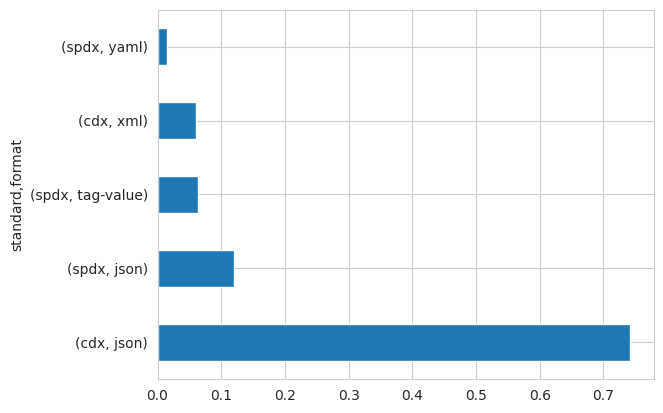

In [16]:
standards.plot(x='proportion',kind='barh', stacked=True)
#plt.savefig('standards.svg', bbox_inches = 'tight', pad_inches = 0)

## 2. Most used file names

In [17]:
filenames = pd.read_csv('../sboms-02-filenames.csv')
print(f"Total filenames: {len(filenames.index)}, unique filenames: {len(filenames['filename'].drop_duplicates())}")

Total filenames: 1168305, unique filenames: 1061904


Text(0, 0.5, 'Filename')

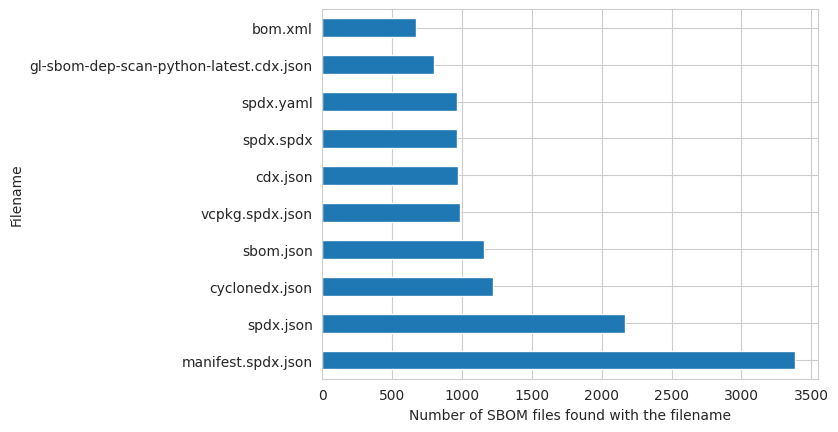

In [18]:
# Get the top 10
filenames_mostused = filenames.value_counts('filename', normalize=False)[:10]

sns.set_style("whitegrid")
ax = filenames_mostused.plot.barh(x='count', y='filename')
#ax.set_xscale('log')
plt.xlabel("Number of SBOM files found with the filename")
plt.ylabel("Filename")

#plt.savefig("popular-filenames.pdf", bbox_inches='tight')

## 3. Popular forges

In [19]:
origins = pd.read_csv("../sboms-03-origins.csv", engine='pyarrow')

In [20]:
origins.axes

[RangeIndex(start=0, stop=123826650, step=1),
 Index(['swhid', 'origin_url'], dtype='object')]

In [21]:
sboms_ori = pd.merge(sboms, origins, on='swhid', how='inner')
sboms_ori.dropna(subset = ['origin_url'], inplace=True)
sboms_ori.axes

[Index([        0,         1,         2,         3,         4,         5,
                6,         7,         8,         9,
        ...
        123826640, 123826641, 123826642, 123826643, 123826644, 123826645,
        123826646, 123826647, 123826648, 123826649],
       dtype='int64', length=123826624),
 Index(['sha1', 'sha1_git', 'swhid', 'score', 'standard', 'version', 'format',
        'origin_url'],
       dtype='object')]

In [22]:
import tldextract as tld
def domain(s: str) -> str:
    if type(s) != str:
        return ""
        
    r = tld.extract(s)
    if len(r.suffix) > 0:
        return f"{r.domain}.{r.suffix}"
    else:
        return f"{r.domain}"
        
sboms_ori['domain'] = origins['origin_url'].apply(lambda x: domain(x))    

In [23]:
sboms_ori_u = sboms_ori.drop_duplicates(['sha1','domain'])
popular_domains = sboms_ori_u.value_counts('domain', normalize=False)

In [24]:
popular_domains

domain
github.com           68702
pypi.org              6274
gitlab.com            2412
bitbucket.org          966
npmjs.com              144
                     ...  
yiyu.plus                1
yoomoney.ru              1
youmi-lausanne.ch        1
youtube-dl.org           1
yubico.com               1
Name: count, Length: 1783, dtype: int64

Text(0, 0.5, 'Forges and package repositories')

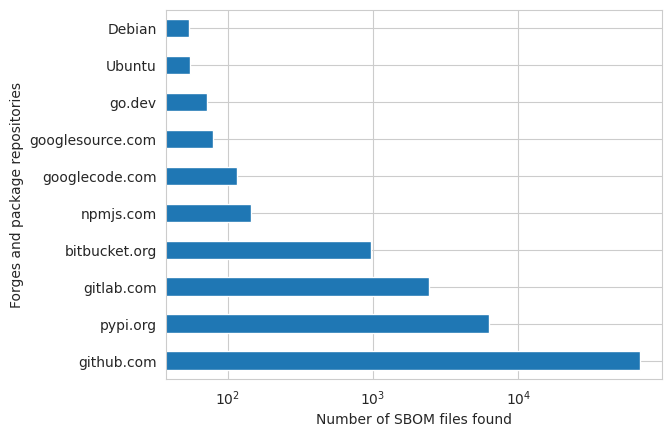

In [25]:
sns.set_style("whitegrid")
ax = popular_domains[:10].plot.barh(x='count', y='domain')
ax.set_xscale('log')
plt.xlabel("Number of SBOM files found")
plt.ylabel("Forges and package repositories")

#plt.savefig('popular-forges.pdf', bbox_inches='tight')

## Total number of commits (revisions)

In [26]:
revisions = pd.read_csv("../sboms-04-revisions.csv", engine='pyarrow')
revisions.axes

[RangeIndex(start=0, stop=76238, step=1),
 Index(['swhid', 'earliest_swhid', 'earliest_ts', 'rev_occurrences'], dtype='object')]

In [27]:
revisions.rev_occurrences.sum()

np.int64(2232518895)